# 수율 저하 Q&A — 파악 방법 · 경우별 원인 · 타정 장애 매핑

이 노트북은 아래 세 질문에 차례로 답합니다. 데이터 구조와 품질 점검은 `EDA_Lek_yield.ipynb` 를 참고하세요.

| 질문 | 장 |
|---|---|
| **Q1.** 이 데이터셋에서 수율 저하는 어떻게 파악할 수 있는가? | Q1 |
| **Q2.** 수율이 저하된 경우별로 원인은 무엇인가? | Q2 |
| **Q3.** 경우별 원인 중 캡핑·라미네이션·스틱킹·바인딩·치핑·더블 인프린트·정제 중량 편차가 있다면 매핑 | Q3 |

### 한눈에 보는 답

| 질문 | 답 |
|---|---|
| **Q1. 어떻게 파악하나?** | ① 배치 결과: `batch_yield` 하위 10%(< 96.97%)를 저수율로 정의 → 92개 배치. ② 생산 중 신호: 타정기 **폐기 카운터**가 수율 손실과 함께 움직임(ρ = 0.74). ③ 손실 시점: 폐기의 **74%가 셋업(본 생산 전)**, 17%가 **생산 중 재시작** 직후에 발생. 두 구간은 전체 기록 시간의 11%에 불과 |
| **Q2. 경우별 원인은?** | **셋업 손실형(63개, 68%)**: 소형 배치·캠페인 첫 배치에서 셋업 폐기 과다 · **재시작 손실형(18개, 20%)**: 정지가 잦고(정상의 7배) 재시작마다 압축력이 흔들려 폐기 과다(1회당 9배), 주말 생산 비율 44% · **정상 운전 배출형(11개, 12%)**: 소형 5 mg 제품에서 운전 중에도 무게 변동으로 배출 |
| **Q3. 타정 장애 매핑** | **정제 중량 편차 → 세 경우 모두 존재** (가장 확실) · **스틱킹/바인딩 → 재시작 손실형(강), 셋업 손실형(약)** · **캡핑/치핑 → 재시작 손실형에서 '가능성'** (최소 경도 저하, 단 중량 편차로도 설명 가능) · **라미네이션 → 근거 없음** · **더블 인프린트 → 데이터 없어 판정 불가** |

> ⚠️ 이 데이터에는 불량 유형 기록이 없어 Q3은 **간접 신호에 기반한 가설**입니다. 실제 불량 검사 기록과의 대조가 필요합니다.

---
## 목차

| 장 | 제목 |
|---|---|
| 0 | 준비: 환경 설정과 데이터 로드 |
| Q1 | 수율 저하를 파악하는 방법 |
| Q2 | 수율 저하 경우별 원인 |
| Q3 | 타정 장애 매핑 |
| 4 | 결론 |

---
## 0. 준비: 환경 설정과 데이터 로드

### 0.1 라이브러리와 경로

노트북이 `notebooks/` 폴더 안에 있으므로, `data/` 폴더가 보일 때까지 상위 폴더로 올라가 저장소 루트를 찾습니다.

In [1]:
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import koreanize_matplotlib  # noqa: F401  (import 만으로 한글 폰트 설정)
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

# ── 저장소 루트 찾기 ──────────────────────────────────
ROOT = Path.cwd()
while not (ROOT / "data" / "Laboratory.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
ZIP_PATH = DATA_DIR / "Process.zip"
print("데이터 경로:", DATA_DIR)

# ── 색상 (노트북 전체 공통) ──────────────────────────
C_NORMAL, C_LOW, C_GRAY, C_TEXT2 = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
PALETTE = {"정상": C_NORMAL, "저수율": C_LOW}
# 경우(케이스) 색상: 고정 순서
CASE_ORDER = ["재시작 손실형", "셋업 손실형", "정상 운전 배출형"]
CASE_COLOR = {"재시작 손실형": "#2a78d6", "셋업 손실형": "#1baf7a", "정상 운전 배출형": "#6250d6", "정상": C_GRAY}
# 생산 단계 색상: 고정 순서
PHASE_ORDER = ["셋업", "재시작", "정지 전환", "정상 운전"]
PHASE_COLOR = {"셋업": "#1baf7a", "재시작": "#2a78d6", "정지 전환": "#eda100", "정상 운전": "#6250d6"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C_TEXT2, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "xtick.color": C_TEXT2, "ytick.color": C_TEXT2,
    "legend.frameon": False, "axes.unicode_minus": False,
})

데이터 경로: /home/user/pharma-manufacturing/data


### 0.2 배치 단위 데이터 로드

- `Laboratory.csv`: 수율, 원자재, 공정 중 검사(IPC)
- `Process.csv`: 공정 요약 변수 (출하 품질 중복 컬럼은 제외)
- API 컬럼의 공백 문자열은 결측으로 바꿉니다.

In [2]:
lab = pd.read_csv(DATA_DIR / "Laboratory.csv", sep=";")
proc = pd.read_csv(DATA_DIR / "Process.csv", sep=";")
for c in ["api_water", "api_total_impurities", "api_l_impurity", "api_ps01", "api_ps05", "api_ps09"]:
    lab[c] = pd.to_numeric(lab[c].astype(str).str.strip().replace("", np.nan), errors="coerce")

DUP = ["Drug release average (%)", "Drug release min (%)", "Residual solvent", "Total impurities", "Impurity O", "Impurity L"]
df = lab.merge(proc.drop(columns=DUP), on=["batch", "code"]).set_index("batch").sort_index()
df["f100k"] = df["size"] / 1e5   # 10만 정 단위 배치 크기 (정규화용)
print("배치 테이블:", df.shape)

배치 테이블: (1005, 82)


### 0.3 시계열에서 생산 단계별 폐기량 계산

타정기 시계열(10초 간격)의 **폐기 카운터(`waste`)** 를 이용해, 각 배치의 폐기 정제가 **어느 생산 단계에서** 나왔는지 나눕니다.

| 생산 단계 | 정의 |
|---|---|
| 셋업 | 생산 카운터(`produced`)가 0인 구간 = 본 생산 전 기계 조정 단계 |
| 재시작 | 본 생산 중 정지했다가 다시 돌기 시작한 뒤 10분 |
| 정지 전환 | 본 생산 중 타정기가 멈춰 있는 구간 (멈추는 순간의 배출이 대부분) |
| 정상 운전 | 본 생산 중 그 밖의 운전 구간 |

- 셋업 구간의 폐기량은 `Process.csv` 의 `startup_waste` 와 거의 같습니다(아래에서 확인).

- 폐기 카운터는 중간에 0으로 리셋되기도 하므로 **증가분만 더해** 배치 총 폐기량을 만듭니다.
- 시각 값에는 일/월 뒤바뀜 문제가 있으므로(`EDA_Lek_yield.ipynb` 3.4절) **샘플 순서**만 사용합니다.
- 압축력 안정성: 각 배치의 정상 운전 중앙값 대비 주압축력의 상대 편차를 구하고, 구간별 90번째 백분위수를 저장합니다.

In [3]:
WIN = 60   # 10분 = 10초 × 60 샘플


def phase_frame(d: pd.DataFrame) -> pd.DataFrame:
    # 원시 시계열에 생산 단계(phase)와 폐기 증가분(dw)을 붙인다.
    d = d.copy()
    d["dw"] = d.groupby("batch").waste.diff().clip(lower=0).fillna(0)
    run = d.tbl_speed > 0
    prev = run.groupby(d.batch).shift(fill_value=False)
    started = (d.produced > 0).groupby(d.batch).cummax()   # 본 생산 시작 여부
    d["restart"] = run & ~prev & started                    # 본 생산 중 재시작만 센다
    seg = d.groupby("batch").restart.cumsum()               # 본 생산 중 몇 번째 운전 구간인가
    k = d.groupby([d.batch, seg]).cumcount()                 # 운전 구간 시작 후 샘플 수
    d["phase"] = np.select([~started, ~run, (seg >= 1) & (k < WIN)], ["셋업", "정지 전환", "재시작"], "정상 운전")
    ref = d[d.phase == "정상 운전"].groupby("batch").main_comp.median()
    d["comp_dev"] = (d.main_comp / d.batch.map(ref) - 1).abs()
    return d


ev_rows = []
with zipfile.ZipFile(ZIP_PATH) as z:
    for c in range(1, 26):
        with z.open(f"Process/{c}.csv") as f:
            raw = pd.read_csv(f, sep=";", usecols=["batch", "tbl_speed", "main_comp", "waste", "produced"])
        d = phase_frame(raw)
        w = d.pivot_table(index="batch", columns="phase", values="dw", aggfunc="sum", fill_value=0)
        n = d.pivot_table(index="batch", columns="phase", values="dw", aggfunc="size", fill_value=0)
        r = w.reindex(columns=PHASE_ORDER, fill_value=0).add_prefix("waste_")
        r = r.join(n.reindex(columns=PHASE_ORDER, fill_value=0).add_prefix("n_"))
        r["n_restart"] = d.groupby("batch").restart.sum()
        r["comp_dev90_setup"] = d[(d.phase == "셋업") & (d.tbl_speed > 0)].groupby("batch").comp_dev.quantile(0.9)
        r["comp_dev90_transition"] = d[d.phase == "재시작"].groupby("batch").comp_dev.quantile(0.9)
        r["comp_dev90_steady"] = d[d.phase == "정상 운전"].groupby("batch").comp_dev.quantile(0.9)
        ev_rows.append(r)

ev = pd.concat(ev_rows).fillna(0)
df = df.join(ev).copy()
print("시계열 요약 변수 추가 후:", df.shape)
print(f"셋업 구간 폐기량 vs Process.startup_waste: 스피어만 ρ = {stats.spearmanr(df['waste_셋업'], df.startup_waste)[0]:.3f}, "
      f"비율 중앙값 = {(df['waste_셋업'] / df.startup_waste).median():.2f}")
df[[f"waste_{p}" for p in PHASE_ORDER] + ["n_restart", "comp_dev90_setup", "comp_dev90_transition", "comp_dev90_steady"]].describe().T

시계열 요약 변수 추가 후: (1005, 94)
셋업 구간 폐기량 vs Process.startup_waste: 스피어만 ρ = 0.999, 비율 중앙값 = 1.00


,count,mean,std,min,25%,50%,75%,max
waste_셋업,"1,005.000","6,188.523","4,649.349",32.000,"2,846.000","4,992.000","8,223.000","45,549.000"
waste_재시작,"1,005.000","1,433.971","3,803.505",0.000,17.000,99.000,577.000,"40,890.000"
waste_정지 전환,"1,005.000",314.974,"1,181.806",0.000,9.000,21.000,149.000,"20,858.000"
waste_정상 운전,"1,005.000",430.686,"1,271.066",0.000,9.000,44.000,239.000,"23,599.000"
n_restart,"1,005.000",7.083,14.490,0.000,1.000,3.000,8.000,234.000
comp_dev90_setup,"1,005.000",0.266,0.194,0.011,0.130,0.211,0.347,1.238
comp_dev90_transition,"1,005.000",0.041,0.065,0.000,0.014,0.024,0.038,0.983
comp_dev90_steady,"1,005.000",0.040,0.050,0.009,0.020,0.024,0.034,0.507


---
## Q1. 수율 저하는 어떻게 파악할 수 있는가?

세 단계로 답합니다.

1. **배치 결과로 파악**: 수율 컬럼으로 저수율 배치를 정의한다 (1.1, 1.2)
2. **생산 중 신호로 파악**: 타정기 폐기 카운터가 수율 손실을 따라가는지 확인한다 (1.3)
3. **손실이 생기는 순간 파악**: 폐기가 어느 생산 단계에서 나오는지 본다 (1.4)

### 1.1 수율 지표

| 컬럼 | 의미 |
|---|---|
| `tbl_yield` | 타정 공정 수율(%) |
| `batch_yield` | 배치 전체 수율(%) — **판단 기준으로 사용** |

In [4]:
r = df[["tbl_yield", "batch_yield"]].corr().iat[0, 1]
print(f"tbl_yield 와 batch_yield 의 상관: {r:.2f}  |  두 값의 차이 중앙값: {(df.tbl_yield - df.batch_yield).median():.2f}%p")
df[["tbl_yield", "batch_yield"]].describe(percentiles=[0.01, 0.05, 0.1, 0.5, 0.9]).T

tbl_yield 와 batch_yield 의 상관: 0.95  |  두 값의 차이 중앙값: 0.00%p


,count,mean,std,min,1%,5%,10%,50%,90%,max
tbl_yield,"1,005.000",98.323,1.078,87.973,94.726,96.551,96.985,98.554,99.290,100.805
batch_yield,"1,005.000",98.256,1.129,87.973,94.333,96.319,96.970,98.485,99.290,100.909


> **해석**
>
> - 두 수율의 상관은 0.95, 차이의 중앙값은 0입니다. 손실 대부분이 **타정 공정**에서 생기므로, 타정기 시계열로 원인을 찾을 수 있습니다.
> - 수율 중앙값은 98.5%이고, 하위 1%는 94.3% 미만으로 **왼쪽 꼬리가 깁니다.** 수율 저하는 일부 배치에서 크게 떨어지는 형태입니다.

### 1.2 저수율 배치 정의

두 가지 기준을 비교합니다.

| 기준 | 정의 | 장점 | 단점 |
|---|---|---|---|
| **절대 기준 (채택)** | `batch_yield` 하위 10% | 단순, 손실 크기 그대로 반영 | 수율이 원래 낮은 제품이 많이 포함됨 |
| 제품 내 상대 기준 (참고) | 같은 제품 중앙값보다 1%p 이상 낮음 | 제품 차이 제거 | 제품별 배치 수가 적으면 불안정 |

절대 기준: batch_yield < 96.97%  →  92개 배치 (9.2%)
상대 기준: 제품 중앙값 - 1%p 이하   →  142개 배치 (14.1%)


is_low_rel,상대 기준 저수율,상대 기준 정상
is_low,,
절대 기준 저수율,79,13
절대 기준 정상,63,850


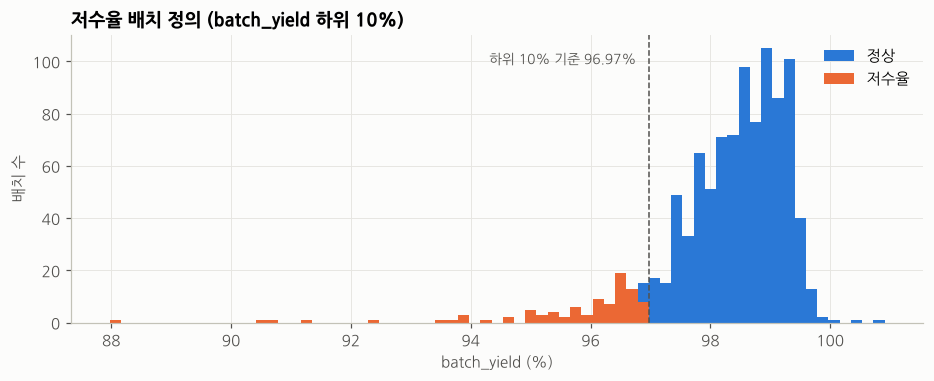

In [5]:
LOW_THR = df.batch_yield.quantile(0.10)
df["is_low"] = df.batch_yield < LOW_THR
df["group"] = np.where(df.is_low, "저수율", "정상")
df["yield_dev"] = df.batch_yield - df.groupby("code").batch_yield.transform("median")
df["is_low_rel"] = df.yield_dev <= -1.0

print(f"절대 기준: batch_yield < {LOW_THR:.2f}%  →  {df.is_low.sum()}개 배치 ({df.is_low.mean():.1%})")
print(f"상대 기준: 제품 중앙값 - 1%p 이하   →  {df.is_low_rel.sum()}개 배치 ({df.is_low_rel.mean():.1%})")
display(pd.crosstab(df.is_low.map({True: "절대 기준 저수율", False: "절대 기준 정상"}),
                    df.is_low_rel.map({True: "상대 기준 저수율", False: "상대 기준 정상"})))

fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.linspace(df.batch_yield.min(), df.batch_yield.max(), 70)
for g in ["정상", "저수율"]:
    ax.hist(df.loc[df.group == g, "batch_yield"], bins=bins, color=PALETTE[g], label=g)
ax.axvline(LOW_THR, color=C_TEXT2, lw=1, ls="--")
ax.annotate(f"하위 10% 기준 {LOW_THR:.2f}%", (LOW_THR, ax.get_ylim()[1] * 0.9), xytext=(-8, 0),
            textcoords="offset points", ha="right", color=C_TEXT2, fontsize=9)
ax.set(title="저수율 배치 정의 (batch_yield 하위 10%)", xlabel="batch_yield (%)", ylabel="배치 수")
ax.legend()
plt.show()

> **해석**
>
> - 절대 기준(하위 10%)으로 **92개 배치**가 저수율입니다. 이 중 79개(86%)는 제품 내 상대 기준으로도 저수율이라 두 기준이 대체로 일치합니다.
> - 절대 기준에만 걸리는 13개는 "원래 수율이 낮은 제품의 평범한 배치"이고, 상대 기준에만 걸리는 63개는 "수율이 높은 제품에서 평소보다 나빴던 배치"입니다.
> - 이 노트북은 **절대 기준**을 쓰되, 원인 분석은 **같은 제품 대비 값**으로 비교해 제품 차이를 걸러냅니다.

### 1.3 생산 중 신호: 폐기 카운터가 수율 손실을 따라가는가?

수율 값은 배치가 끝나야 알 수 있습니다. 생산 중에 수율 저하를 알아채려면 **실시간 신호**가 필요합니다.
타정기의 폐기 카운터로 계산한 폐기율(폐기 정제 수 / 배치 크기)이 실제 수율 손실(100 − `tbl_yield`)을 얼마나 따라가는지 확인합니다.

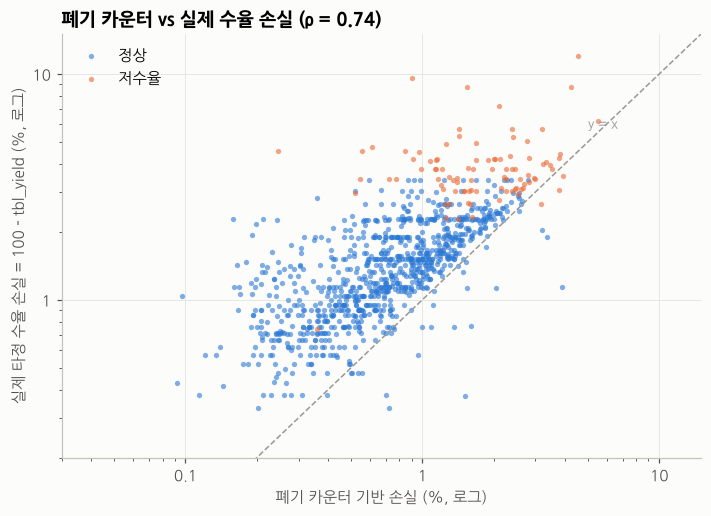

폐기 카운터가 설명하는 손실 비중(배치별 중앙값): 55%


In [6]:
df["waste_total"] = df[[f"waste_{p}" for p in PHASE_ORDER]].sum(axis=1)
df["counter_loss_pct"] = df.waste_total / df["size"] * 100
df["yield_loss_pct"] = 100 - df.tbl_yield
rho = stats.spearmanr(df.counter_loss_pct, df.yield_loss_pct)[0]
share = (df.counter_loss_pct / df.yield_loss_pct.replace(0, np.nan)).clip(upper=2).median()

fig, ax = plt.subplots(figsize=(7.5, 5))
for g in ["정상", "저수율"]:
    d = df[df.group == g]
    ax.scatter(d.counter_loss_pct, d.yield_loss_pct, s=12, alpha=0.6, color=PALETTE[g], label=g, linewidths=0)
lim = [0.03, 15]
ax.plot(lim, lim, color=C_GRAY, lw=1, ls="--")
ax.text(5, 5 * 1.15, "y = x", color=C_GRAY, fontsize=9)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=[0.2, 15],
       xlabel="폐기 카운터 기반 손실 (%, 로그)", ylabel="실제 타정 수율 손실 = 100 - tbl_yield (%, 로그)",
       title=f"폐기 카운터 vs 실제 수율 손실 (ρ = {rho:.2f})")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.legend(loc="upper left")
plt.show()
print(f"폐기 카운터가 설명하는 손실 비중(배치별 중앙값): {share:.0%}")

> **해석**
>
> - 폐기 카운터로 계산한 손실과 실제 수율 손실의 순위 상관은 **ρ = 0.74**입니다. 저수율 배치(주황)는 오른쪽 위에 모여 있습니다.
>   → **폐기 카운터를 실시간으로 보면 생산 중에도 수율 저하를 조기에 알아챌 수 있습니다.**
> - 다만 카운터가 잡는 손실은 실제 손실의 약 **55%(중앙값)** 입니다. 나머지는 검사용 샘플, 분진, 계량 차이 등 카운터에 기록되지 않는 손실로 보입니다 **(추정)**.
>   따라서 카운터는 "수율 저하의 신호"로는 유용하지만 손실 전체를 설명하지는 못합니다.

### 1.4 손실이 생기는 순간: 생산 단계별 폐기 비중

0.3절에서 나눈 생산 단계별로, **운전 시간 비중**과 **폐기량 비중**을 비교합니다.

,시간 비중,폐기 비중,10초당 폐기 정제 수
셋업,6.8%,74.0%,19.49
재시작,4.6%,17.1%,6.60
정지 전환,24.9%,3.8%,0.27
정상 운전,63.7%,5.1%,0.14


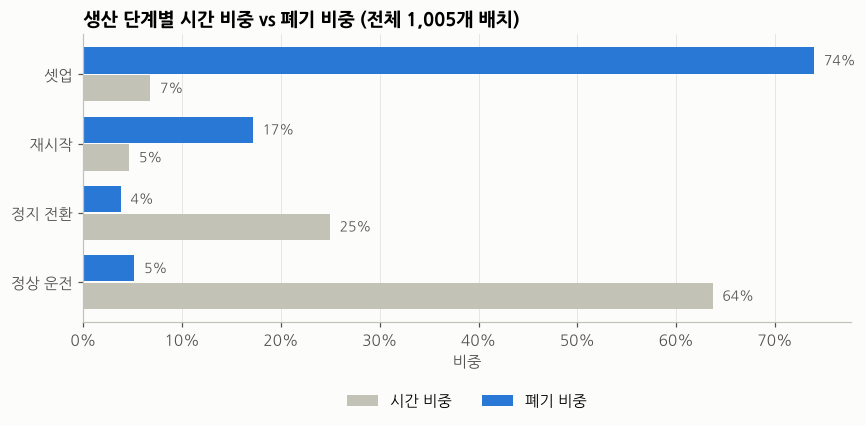

In [7]:
tot_w = df[[f"waste_{p}" for p in PHASE_ORDER]].sum()
tot_n = df[[f"n_{p}" for p in PHASE_ORDER]].sum()
phase_share = pd.DataFrame({
    "시간 비중": tot_n.values / tot_n.sum(),
    "폐기 비중": tot_w.values / tot_w.sum(),
}, index=PHASE_ORDER)
phase_share["10초당 폐기 정제 수"] = tot_w.values / tot_n.values
display(phase_share.style.format({"시간 비중": "{:.1%}", "폐기 비중": "{:.1%}", "10초당 폐기 정제 수": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(PHASE_ORDER))
ax.barh(y + 0.2, phase_share["시간 비중"], height=0.38, color="#c3c2b7", label="시간 비중")
ax.barh(y - 0.2, phase_share["폐기 비중"], height=0.38, color=C_NORMAL, label="폐기 비중")
for yi, v in zip(y, phase_share["폐기 비중"]):
    ax.text(v + 0.01, yi - 0.2, f"{v:.0%}", va="center", fontsize=9, color=C_TEXT2)
for yi, v in zip(y, phase_share["시간 비중"]):
    ax.text(v + 0.01, yi + 0.2, f"{v:.0%}", va="center", fontsize=9, color=C_TEXT2)
ax.set_yticks(y, PHASE_ORDER)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="생산 단계별 시간 비중 vs 폐기 비중 (전체 1,005개 배치)", xlabel="비중")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()

**예시 배치로 보기** — 저수율 배치 하나의 타정 속도와 폐기 증가분을 생산 단계 색으로 표시합니다.

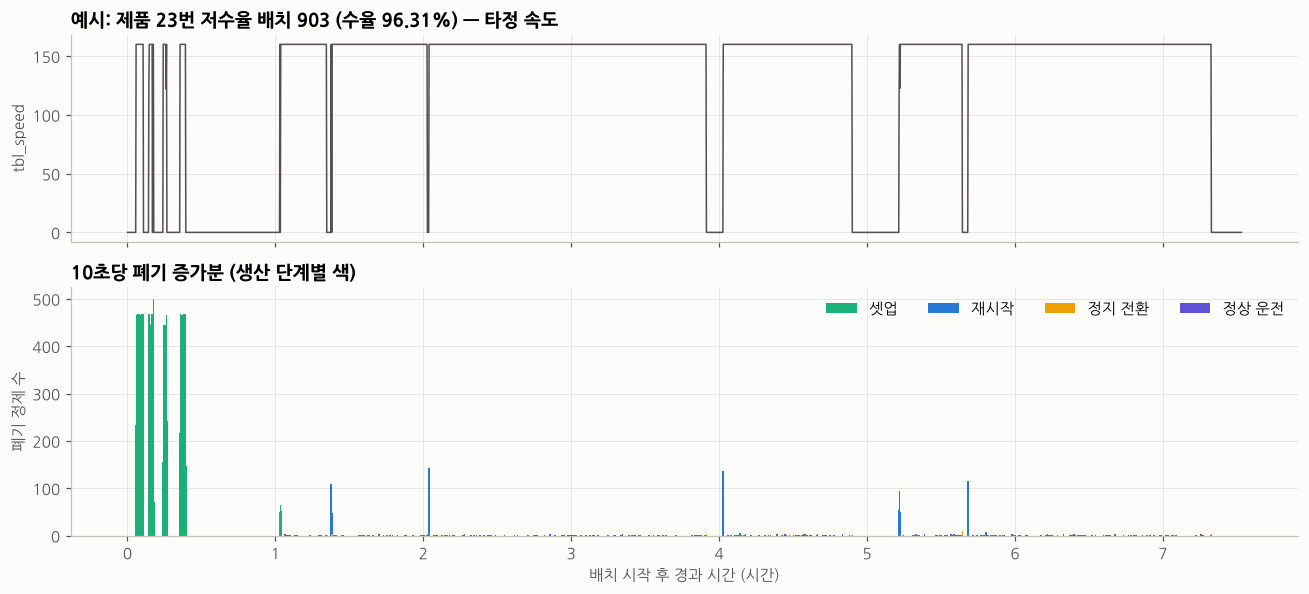

In [8]:
EX_CODE = 23
cand = df[(df.code == EX_CODE) & df.is_low]
ex_b = cand.batch_yield.sub(cand.batch_yield.median()).abs().idxmin()
with zipfile.ZipFile(ZIP_PATH) as z, z.open(f"Process/{EX_CODE}.csv") as f:
    raw = pd.read_csv(f, sep=";", usecols=["batch", "tbl_speed", "main_comp", "waste", "produced"])
ex = phase_frame(raw[raw.batch == ex_b]).reset_index(drop=True)
ex["hours"] = ex.index * 10 / 3600

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
axes[0].plot(ex.hours, ex.tbl_speed, color=C_TEXT2, lw=1)
axes[0].set(title=f"예시: 제품 {EX_CODE}번 저수율 배치 {ex_b} (수율 {df.loc[ex_b, 'batch_yield']:.2f}%) — 타정 속도", ylabel="tbl_speed")
for p in PHASE_ORDER:
    m = ex.phase == p
    axes[1].bar(ex.hours[m], ex.dw[m], width=10 / 3600 * 4, color=PHASE_COLOR[p], label=p)
axes[1].set(title="10초당 폐기 증가분 (생산 단계별 색)", ylabel="폐기 정제 수", xlabel="배치 시작 후 경과 시간 (시간)")
axes[1].legend(ncol=4, loc="upper right")
plt.tight_layout()
plt.show()

> **해석**
>
> - **셋업 단계는 전체 기록 시간의 6.8%인데 폐기의 74%를 차지합니다.** 생산 중 재시작 10분 구간도 시간 4.6%에 폐기 17%입니다.
> - 반대로 **정상 운전은 기록 시간의 64%를 차지하지만 폐기는 5%뿐**입니다. 10초당 폐기량으로 보면 셋업(19.5정)은 정상 운전(0.14정)의 약 140배입니다.
> - 예시 배치(제품 23번, 배치 903)에서도 폐기 막대는 셋업(초록)에 집중되고, 이후에는 **정지 후 재시작할 때마다 파란 막대가 하나씩** 튀어 오릅니다.
> - 결론: 수율 손실은 운전 내내 조금씩 생기는 것이 아니라 **"멈췄다가 시작하는 순간"** 에 집중됩니다.

#### ✅ Q1 답변

| 단계 | 방법 | 이 데이터에서의 결과 |
|---|---|---|
| 배치 결과 | `batch_yield` 하위 10% 기준 | 96.97% 미만, 92개 배치 |
| 생산 중 신호 | 폐기 카운터 증가분 ÷ 배치 크기 | 실제 수율 손실과 ρ = 0.74 (손실의 약 55%를 포착) |
| 손실 시점 | 폐기를 생산 단계별로 분해 | 셋업 74% · 재시작 17% · 정지 전환 4% · 정상 운전 5% |

---
## Q2. 수율이 저하된 경우별로 원인은 무엇인가?

### 2.1 경우(케이스) 나누기: 초과 폐기가 어느 단계에서 나왔나

Q1에서 폐기가 생산 단계별로 크게 다르다는 것을 확인했습니다. 이를 이용해 저수율 배치를 **경우별로** 나눕니다.

1. 각 배치의 단계별 폐기량을 **10만 정당**으로 바꿉니다 (배치 크기 차이 제거).
2. 같은 제품의 **정상 배치 중앙값**을 빼서 "초과 폐기량"을 구합니다 (제품 차이 제거).
3. 초과 폐기량이 가장 큰 단계를 그 배치의 **경우**로 정합니다.

| 경우 | 의미 |
|---|---|
| 재시작 손실형 | 본 생산 중 정지 → 재시작할 때 + 멈출 때(정지 전환) 폐기가 많음 |
| 셋업 손실형 | 본 생산 전 기계 조정(셋업) 단계에서 폐기가 많음 |
| 정상 운전 배출형 | 안정 운전 중에도 폐기가 계속 나옴 |

정지 전환 구간의 폐기는 정지-재시작 사이클의 일부이므로 **재시작 손실형에 합칩니다.**

In [9]:
for p in PHASE_ORDER:
    df[f"rate_{p}"] = df[f"waste_{p}"] / df.f100k
df["rate_재시작+정지"] = df["rate_재시작"] + df["rate_정지 전환"]

CASE_PHASES = {"셋업 손실형": "rate_셋업", "재시작 손실형": "rate_재시작+정지", "정상 운전 배출형": "rate_정상 운전"}
normal_med = df[~df.is_low].groupby("code")[list(CASE_PHASES.values())].median()
excess = pd.DataFrame({case: df[col] - df.code.map(normal_med[col]) for case, col in CASE_PHASES.items()})
df["case"] = np.where(df.is_low, excess.idxmax(axis=1), "정상")

case_cnt = df.loc[df.is_low, "case"].value_counts().reindex(CASE_ORDER)
display(pd.DataFrame({"배치 수": case_cnt, "저수율 중 비중": case_cnt / case_cnt.sum()}).style.format({"저수율 중 비중": "{:.0%}"}))

# 경우별 초과 폐기량 (10만 정당, 중앙값)
excess.loc[df.is_low].groupby(df.loc[df.is_low, "case"]).median().reindex(CASE_ORDER).round(0)

,배치 수,저수율 중 비중
case,,
재시작 손실형,18,20%
셋업 손실형,63,68%
정상 운전 배출형,11,12%


,셋업 손실형,재시작 손실형,정상 운전 배출형
case,,,
재시작 손실형,-100.000,999.000,20.000
셋업 손실형,805.000,14.000,4.000
정상 운전 배출형,-100.000,37.000,159.000


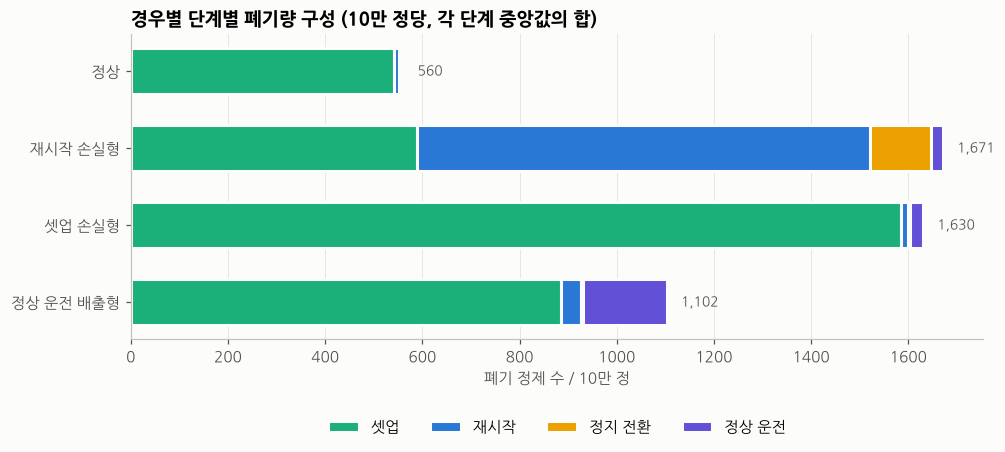

In [10]:
# 경우별 단계별 폐기율 구성 (10만 정당, 중앙값) — 정상 배치와 비교
comp = df.groupby("case")[[f"rate_{p}" for p in PHASE_ORDER]].median().reindex(["정상"] + CASE_ORDER)
comp.columns = PHASE_ORDER

fig, ax = plt.subplots(figsize=(10, 3.6))
left = np.zeros(len(comp))
for p in PHASE_ORDER:
    ax.barh(comp.index, comp[p], left=left, color=PHASE_COLOR[p], label=p, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    left += comp[p].values
for yi, v in enumerate(left):
    ax.text(v + 30, yi, f"{v:,.0f}", va="center", fontsize=9, color=C_TEXT2)
ax.invert_yaxis()
ax.set(title="경우별 단계별 폐기량 구성 (10만 정당, 각 단계 중앙값의 합)", xlabel="폐기 정제 수 / 10만 정")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.show()

> **해석**
>
> - 저수율 92개 중 **셋업 손실형이 63개(68%)** 로 가장 많고, **재시작 손실형 18개(20%)**, **정상 운전 배출형 11개(12%)** 입니다.
> - 경우별 초과 폐기량(같은 제품 정상 배치 대비, 10만 정당)은 셋업 손실형이 셋업 단계에서 +805정,
>   재시작 손실형이 재시작·정지 단계에서 +999정, 정상 운전 배출형이 정상 운전 단계에서 +159정입니다.
> - 막대그래프에서 정상 배치의 폐기는 거의 전부 셋업(초록)이고 합계가 10만 정당 560정인 반면,
>   **재시작 손실형은 파란색(재시작)과 노란색(정지 전환)이 크게 늘어** 합계가 3배(1,671정)입니다.

### 2.2 경우별 특징 비교

각 경우의 배치가 **어떤 조건에서 생산되었는지**, 그리고 **어떤 운전 신호를 보였는지** 정상 배치와 비교합니다.
제품 차이를 없애기 위해 공정 값은 **같은 제품의 중앙값 대비 비율(1.0 = 제품 평균 수준)** 로 바꿔 봅니다.

| 변수 | 의미 |
|---|---|
| `restart_per_100k` | 10만 정당 재시작 횟수 |
| `waste_per_restart` | 재시작 1회당 폐기 정제 수 (재시작 + 정지 전환 폐기 ÷ 재시작 횟수) |
| `comp_dev90_setup` | 셋업 중 주압축력이 정상 운전 수준에서 벗어난 정도(90번째 백분위수) |
| `comp_dev90_transition` | 재시작 10분 동안 같은 지표 |
| `comp_dev90_steady` | 정상 운전 중 같은 지표 |
| `rsd_weight_rel` | 정제 무게 상대표준편차(IPC) — 제품 대비 |
| `ejection_max_rel` | 최대 배출력 — 제품 대비 |
| `comp_force_rel` | 평균 주압축력 — 제품 대비 |
| `hardness_min_rel` | 최소 경도(IPC) — 제품 대비 |

In [11]:
g = df.groupby("code")
rel = lambda c: df[c] / g[c].transform("median")
df["restart_per_100k"] = df.n_restart / df.f100k
df["waste_per_restart"] = (df["waste_재시작"] + df["waste_정지 전환"]) / df.n_restart.replace(0, np.nan)
df["rsd_weight_rel"] = rel("tbl_rsd_weight")
df["ejection_max_rel"] = rel("ejection_max")
df["comp_force_rel"] = rel("main_CompForce mean")
df["hardness_min_rel"] = rel("tbl_min_hardness")
df["fom_rel"] = rel("fom_mean")
df["tensile_rel"] = rel("tbl_tensile")

# 캠페인 정보 (시계열의 campaign 컬럼)
camp = []
with zipfile.ZipFile(ZIP_PATH) as z:
    for c in range(1, 26):
        with z.open(f"Process/{c}.csv") as f:
            camp.append(pd.read_csv(f, sep=";", usecols=["batch", "campaign"]).drop_duplicates("batch").set_index("batch"))
df = df.join(pd.concat(camp))
df["first_in_campaign"] = df.groupby("campaign").cumcount() == 0
df["is_small"] = df["size"] <= 600_000
df["is_weekend"] = df.weekend.eq("yes")

STRUCT = {"is_small": "소형 배치(≤600k) 비율", "first_in_campaign": "캠페인 첫 배치 비율", "is_weekend": "주말 생산 비율"}
OPER = ["restart_per_100k", "waste_per_restart", "comp_dev90_setup", "comp_dev90_transition", "comp_dev90_steady",
        "rsd_weight_rel", "ejection_max_rel", "comp_force_rel", "hardness_min_rel"]

order = ["정상"] + CASE_ORDER
prof_struct = df.groupby("case")[list(STRUCT)].mean().reindex(order).rename(columns=STRUCT)
prof_struct.insert(0, "배치 수", df.case.value_counts().reindex(order))
strength_mix = pd.crosstab(df.case, df.strength, normalize="index").reindex(order)[["5MG", "10M", "20M", "40M"]]
tbl = prof_struct.join(strength_mix.add_prefix("함량 "))
display(tbl.style.format({c: ("{:,.0f}" if c == "배치 수" else "{:.0%}") for c in tbl.columns}))

,배치 수,소형 배치(≤600k) 비율,캠페인 첫 배치 비율,주말 생산 비율,함량 5MG,함량 10M,함량 20M,함량 40M
case,,,,,,,,
정상,913,21%,16%,5%,21%,23%,46%,9%
재시작 손실형,18,33%,39%,44%,33%,11%,44%,11%
셋업 손실형,63,70%,48%,3%,63%,3%,19%,14%
정상 운전 배출형,11,82%,9%,0%,82%,0%,9%,9%


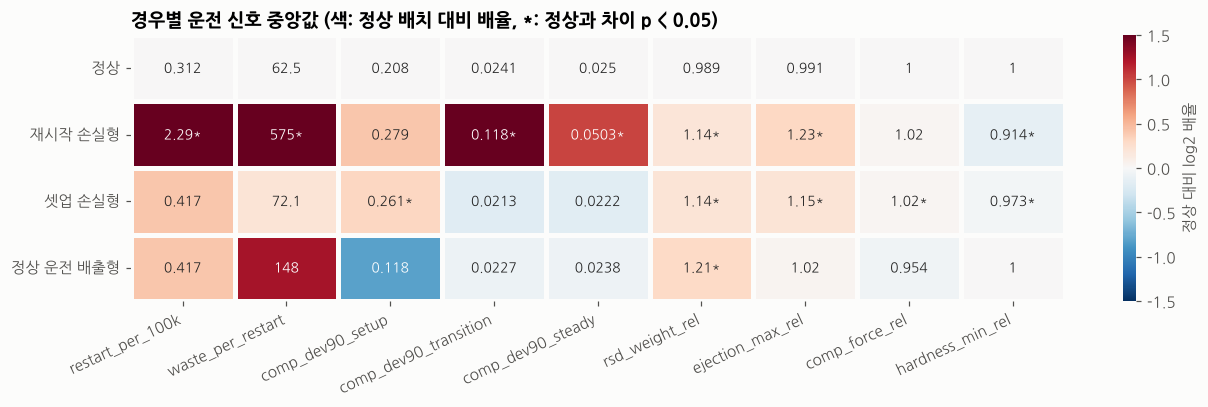

In [12]:
prof_oper = df.groupby("case")[OPER].median().reindex(order)


def mw_p(col, case):
    a, b = df.loc[df.case == case, col].dropna(), df.loc[df.case == "정상", col].dropna()
    return stats.mannwhitneyu(a, b).pvalue


pmat = pd.DataFrame({c: [np.nan] + [mw_p(c, k) for k in CASE_ORDER] for c in OPER}, index=order)
ratio = prof_oper / prof_oper.loc["정상"]

fig, ax = plt.subplots(figsize=(12, 3.8))
annot = prof_oper.copy().astype(object)
for i in prof_oper.index:
    for c in OPER:
        star = "" if i == "정상" else ("*" if pmat.loc[i, c] < 0.05 else "")
        annot.loc[i, c] = f"{prof_oper.loc[i, c]:.3g}{star}"
sns.heatmap(np.log2(ratio.astype(float)), cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, annot=annot, fmt="",
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "정상 대비 log2 배율"}, ax=ax, annot_kws={"size": 9})
ax.grid(False)
ax.set(title="경우별 운전 신호 중앙값 (색: 정상 배치 대비 배율, *: 정상과 차이 p < 0.05)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=25)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

> **해석**
>
> **셋업 손실형 (63개)**
> - **소형 배치가 70%**(정상 21%), **캠페인 첫 배치가 48%**(정상 16%), 5 mg 제품이 63%입니다.
> - 셋업 중 압축력 변동이 정상보다 약간 큽니다(0.261 vs 0.208, p < 0.05). 무게 변동·배출력도 약간 높습니다.
> - → 제품 교체 직후 셋업에서 충전량·압축력을 맞추는 과정의 손실이 크고, **작은 배치에서는 그 고정 손실이 수율을 크게 깎습니다.**
>
> **재시작 손실형 (18개)**
> - 10만 정당 재시작 횟수가 **정상의 7배**(2.29 vs 0.31), 재시작 1회당 폐기도 **9배**(575 vs 62정)입니다.
> - **재시작 구간 압축력 변동이 정상의 약 5배**(0.118 vs 0.024)이고, 정상 운전 중에도 2배입니다. 배출력도 높고(1.23배) 최소 경도는 낮습니다(0.91배).
> - **주말 생산 비율이 44%**로 정상(5%)의 약 9배입니다. 표본은 18개로 작지만 눈에 띄는 차이입니다.
> - 이 그룹에는 전체 최저 수율 배치 789도 포함됩니다.
>
> **정상 운전 배출형 (11개)**
> - 82%가 소형 5 mg 제품입니다. 운전 중 압축력 변동은 정상과 같지만 **IPC 무게 변동(RSD)이 1.21배**로 높습니다.
> - 표본이 11개로 작고, 압축력 같은 공정 신호로는 원인이 잘 드러나지 않습니다.

### 2.3 재시작 손실형 자세히 보기: 횟수 문제인가, 1회당 손실 문제인가?

재시작 손실형은 저수율의 대부분을 차지합니다. 손실 = **재시작 횟수 × 재시작 1회당 폐기량** 이므로 두 요인을 나누어 봅니다.

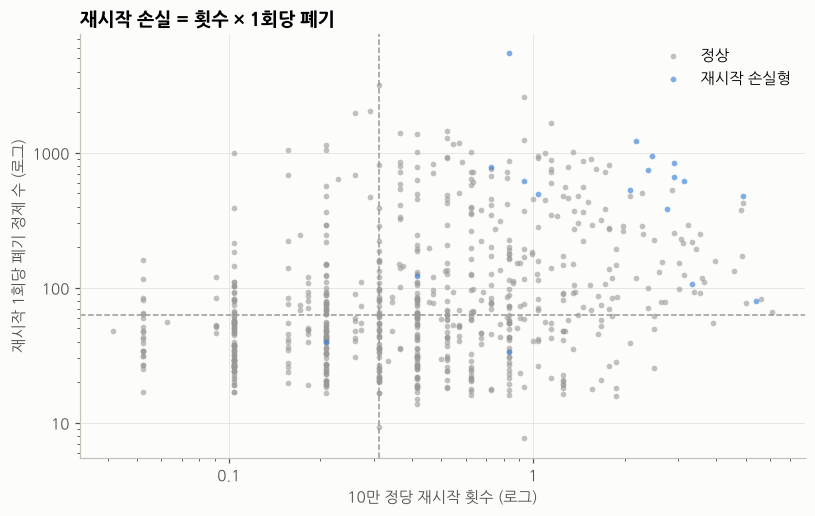

col_0,1회당 폐기 많음,1회당 폐기 보통
row_0,,
재시작 보통,0,1
재시작 잦음,16,1


In [13]:
d = df[df.case.isin(["정상", "재시작 손실형"])]
fig, ax = plt.subplots(figsize=(8.5, 5))
for case, color in [("정상", C_GRAY), ("재시작 손실형", CASE_COLOR["재시작 손실형"])]:
    s = d[d.case == case]
    ax.scatter(s.restart_per_100k, s.waste_per_restart, s=14, alpha=0.6, color=color, label=case, linewidths=0)
ax.set(xscale="log", yscale="log", xlabel="10만 정당 재시작 횟수 (로그)", ylabel="재시작 1회당 폐기 정제 수 (로그)",
       title="재시작 손실 = 횟수 × 1회당 폐기")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.axvline(df.loc[df.case == "정상", "restart_per_100k"].median(), color=C_GRAY, lw=1, ls="--")
ax.axhline(df.loc[df.case == "정상", "waste_per_restart"].median(), color=C_GRAY, lw=1, ls="--")
ax.legend()
plt.show()

# 정상 중앙값 기준 4분면 분류
nr = df.loc[df.case == "정상", ["restart_per_100k", "waste_per_restart"]].median()
rs = df[df.case == "재시작 손실형"]
quad = pd.crosstab(np.where(rs.restart_per_100k > nr.restart_per_100k, "재시작 잦음", "재시작 보통"),
                   np.where(rs.waste_per_restart > nr.waste_per_restart, "1회당 폐기 많음", "1회당 폐기 보통"))
quad

In [14]:
# 재시작 1회당 폐기량과 재시작 구간 압축력 편차의 관계 (전체 배치, 제품 보정)
df["wpr_rel"] = df.waste_per_restart / df.groupby("code").waste_per_restart.transform("median")
df["cdev_tr_rel"] = df.comp_dev90_transition / df.groupby("code").comp_dev90_transition.transform("median")
rho_a = stats.spearmanr(df.cdev_tr_rel, df.wpr_rel, nan_policy="omit")[0]
rho_b = stats.spearmanr(df.cdev_tr_rel, df.yield_dev, nan_policy="omit")[0]
print(f"재시작 구간 압축력 편차(제품 대비) vs 재시작 1회당 폐기(제품 대비): ρ = {rho_a:.2f}")
print(f"재시작 구간 압축력 편차(제품 대비) vs 수율 편차(yield_dev):        ρ = {rho_b:.2f}")

재시작 구간 압축력 편차(제품 대비) vs 재시작 1회당 폐기(제품 대비): ρ = 0.56
재시작 구간 압축력 편차(제품 대비) vs 수율 편차(yield_dev):        ρ = -0.27


> **해석**
>
> - 재시작 손실형 18개 중 **16개가 "재시작이 잦고 + 1회당 폐기도 많은"** 배치입니다. 두 요인이 함께 나타납니다.
> - 전체 배치에서도 재시작 구간 압축력 변동이 클수록 재시작 1회당 폐기가 많고(ρ = 0.56), 수율이 낮습니다(ρ = −0.27).
>   → 재시작 직후 **충전량이 안정되지 않아 압축력이 흔들리고**, 허용 범위를 벗어난 정제가 자동 배출되는 흐름으로 해석됩니다 **(추정)**.

#### ✅ Q2 답변

| 경우 | 저수율 중 비중 | 언제 손실이 나는가 | 원인 (데이터 근거) |
|---|---|---|---|
| **셋업 손실형** | 63개 (68%) | 본 생산 전 기계 조정 | ① **소형 배치**: 거의 고정된 셋업 손실이 작은 배치 크기에서 수율을 크게 깎음 (소형 비율 70% vs 21%) ② **제품 교체 직후(캠페인 첫 배치)** 셋업 (48% vs 16%) ③ 셋업 중 압축력 변동이 약간 큼 |
| **재시작 손실형** | 18개 (20%) | 본 생산 중 정지 → 재시작 | ① **정지가 잦음** (정상의 7배) ② **재시작 시 압축력(충전량) 불안정** → 1회당 폐기 9배 ③ 주말 생산 비율 높음 (44% vs 5%) — 인력·대응 차이 가능성 |
| **정상 운전 배출형** | 11개 (12%) | 안정 운전 중 | 소형 5 mg 제품에서 **정제 무게 변동**이 큼. 공정 신호로는 원인 불명확 (표본 작음) |

---
## Q3. 타정 장애 매핑

참고 자료(「의약품 제조 11. 정제 타정 장애의 종류, 원인 및 해결 방법」)의 7가지 타정 장애가
Q2의 경우들에 **존재하는지**, 존재한다면 어느 경우와 연결되는지 확인합니다.

⚠️ **전제**: 이 데이터에는 **장애 종류 기록(불량 유형 코드)이 없습니다.** 폐기 카운터는 "몇 개가 버려졌는지"만 알려줍니다.
따라서 각 장애의 **원인으로 알려진 공정 조건**과 **결과로 나타나는 물성 변화**를 데이터에서 찾아 **간접 신호**로 판정합니다.

### 3.1 장애별 데이터 신호 정의

| 장애 | 참고 자료의 원인 | 데이터에서 볼 수 있는 신호 | 신호 변수 (제품 대비) | 판정 방향 |
|---|---|---|---|---|
| 정제 중량 편차 | 충진 깊이 불균일, 유동성 저하, 속도 과도 | 정제 무게 변동 ↑, 압축력 변동 ↑ (압축력은 충전량을 반영) | `rsd_weight_rel`, `comp_dev90_setup`, `comp_dev90_transition`, `comp_dev90_steady` | 높음 |
| 스틱킹 / 바인딩 | 활택제 부족, 마찰 ↑, 펀치·다이 표면 문제 | 배출력 ↑ (다이·펀치와의 마찰이 커지면 정제를 밀어내는 힘이 커짐) | `ejection_max_rel` | 높음 |
| 캡핑 | 과도한 압축력, 결합력 부족, 수분 부족, 미세분말 과다 | 압축력 ↑, 최소 경도 ↓ | `comp_force_rel`, `hardness_min_rel` | 높음 / 낮음 |
| 라미네이션 | 공기 함유(충진 속도), 과도한 압력, 결합력 부족 | 충진 장치 속도 ↑, 압축력 ↑ | `fom_rel`, `comp_force_rel` | 높음 |
| 치핑 | 과도한 압축력, 정제 취약, 펀치·다이 손상 | 압축력 ↑, 최소 경도 ↓ | `comp_force_rel`, `hardness_min_rel` | 높음 / 낮음 |
| 더블 인프린트 | 펀치 상하 움직임 불균형, 펀치 디자인 | **해당 변수 없음** (각인 검사 기록 없음) | — | 판정 불가 |

- 스틱킹과 바인딩은 모두 배출력 상승으로 나타나 **데이터로 구분할 수 없어** 하나로 묶습니다.
- 캡핑과 치핑은 같은 신호(압축력 ↑, 경도 ↓)를 공유하므로 **함께 판정**합니다.

### 3.2 신호 판정 방법

1. 각 신호 변수에 대해 **정상 배치의 90번째 백분위수**(낮음 방향은 10번째)를 기준선으로 잡습니다.
   → 정상 배치에서는 정의상 약 10%가 기준선을 넘습니다.
2. 각 경우의 배치 중 기준선을 넘는 비율을 구하고, 정상 배치 대비 **배율(리프트)** 과 피셔 정확 검정 p값을 계산합니다.
3. 판정: 리프트 ≥ 2 이고 p < 0.05 → **존재(강)**, 리프트 ≥ 1.5 이고 p < 0.1 → **존재(약)**, 그 밖 → **근거 없음**

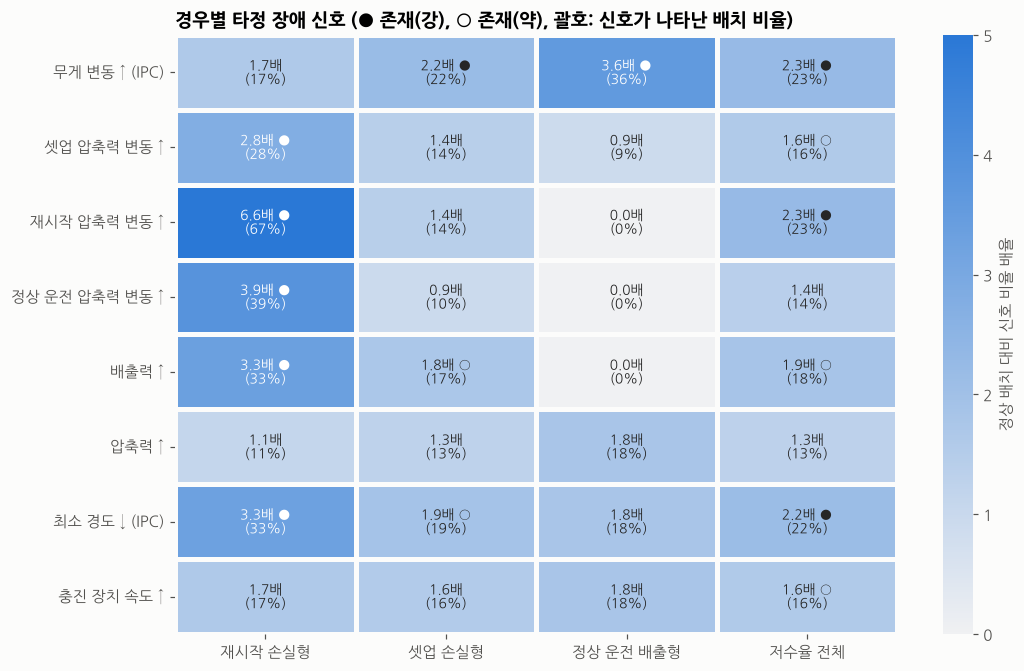

In [15]:
SIGNALS = {
    # 신호 이름: (변수, 방향)
    "무게 변동 ↑ (IPC)": ("rsd_weight_rel", "high"),
    "셋업 압축력 변동 ↑": ("comp_dev90_setup", "high"),
    "재시작 압축력 변동 ↑": ("comp_dev90_transition", "high"),
    "정상 운전 압축력 변동 ↑": ("comp_dev90_steady", "high"),
    "배출력 ↑": ("ejection_max_rel", "high"),
    "압축력 ↑": ("comp_force_rel", "high"),
    "최소 경도 ↓ (IPC)": ("hardness_min_rel", "low"),
    "충진 장치 속도 ↑": ("fom_rel", "high"),
}
normal = df[df.case == "정상"]
for name, (col, how) in SIGNALS.items():
    thr = normal[col].quantile(0.9 if how == "high" else 0.1)
    hit = (df[col] > thr) if how == "high" else (df[col] < thr)
    df[f"sig::{name}"] = hit.astype(float).where(df[col].notna())   # 결측은 판정 제외


def judge(lift, p):
    if lift >= 2 and p < 0.05:
        return "존재(강)"
    if lift >= 1.5 and p < 0.1:
        return "존재(약)"
    return "근거 없음"


rows = []
for name in SIGNALS:
    s = df[f"sig::{name}"]
    base = s[df.case == "정상"].dropna().astype(bool)
    for case in CASE_ORDER + ["저수율 전체"]:
        m = df.is_low if case == "저수율 전체" else df.case == case
        x = s[m].dropna().astype(bool)
        table = [[x.sum(), (~x).sum()], [base.sum(), (~base).sum()]]
        p = stats.fisher_exact(table, alternative="greater").pvalue
        lift = x.mean() / base.mean()
        rows.append({"신호": name, "경우": case, "신호 비율": x.mean(), "정상 배치 비율": base.mean(), "리프트": lift, "p값": p, "판정": judge(lift, p)})
sig = pd.DataFrame(rows)

lift_mat = sig.pivot(index="신호", columns="경우", values="리프트").reindex(index=list(SIGNALS), columns=CASE_ORDER + ["저수율 전체"])
judge_mat = sig.pivot(index="신호", columns="경우", values="판정").reindex(index=list(SIGNALS), columns=CASE_ORDER + ["저수율 전체"])
rate_mat = sig.pivot(index="신호", columns="경우", values="신호 비율").reindex(index=list(SIGNALS), columns=CASE_ORDER + ["저수율 전체"])

annot = lift_mat.copy().astype(object)
mark = {"존재(강)": " ●", "존재(약)": " ○", "근거 없음": ""}
for i in annot.index:
    for c in annot.columns:
        annot.loc[i, c] = f"{lift_mat.loc[i, c]:.1f}배{mark[judge_mat.loc[i, c]]}\n({rate_mat.loc[i, c]:.0%})"

fig, ax = plt.subplots(figsize=(10, 6.2))
sns.heatmap(lift_mat.astype(float), cmap=sns.light_palette("#2a78d6", as_cmap=True), vmin=0, vmax=5,
            annot=annot, fmt="", linewidths=2, linecolor="#fcfcfb", annot_kws={"size": 9},
            cbar_kws={"label": "정상 배치 대비 신호 비율 배율"}, ax=ax)
ax.grid(False)
ax.set(title="경우별 타정 장애 신호 (● 존재(강), ○ 존재(약), 괄호: 신호가 나타난 배치 비율)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

> **해석**
>
> - **재시작 손실형**은 거의 모든 신호가 강하게 나타납니다. 재시작 압축력 변동 67%(6.6배), 정상 운전 압축력 변동 39%(3.9배),
>   배출력 ↑ 33%(3.3배), 최소 경도 ↓ 33%(3.3배), 셋업 압축력 변동 28%(2.8배).
> - **셋업 손실형**은 IPC 무게 변동 ↑(22%, 2.2배)이 강하고, 배출력 ↑(1.8배)과 최소 경도 ↓(1.9배)는 약한 신호입니다.
> - **정상 운전 배출형**은 IPC 무게 변동 ↑(36%, 3.6배)만 강합니다.
> - **압축력 ↑(과도한 압축력)** 과 **충진 장치 속도 ↑** 은 어느 경우에서도 뚜렷하지 않습니다(저수율 전체에서 충진 속도 1.6배로 약한 신호만 있음).

### 3.3 장애별 매핑 결과

In [16]:
DEFECT_SIGNALS = {
    "정제 중량 편차": ["무게 변동 ↑ (IPC)", "셋업 압축력 변동 ↑", "재시작 압축력 변동 ↑", "정상 운전 압축력 변동 ↑"],
    "스틱킹 / 바인딩": ["배출력 ↑"],
    "캡핑 / 치핑": ["압축력 ↑", "최소 경도 ↓ (IPC)"],
    "라미네이션": ["충진 장치 속도 ↑", "압축력 ↑"],
    "더블 인프린트": [],
}
RANK = {"존재(강)": 2, "존재(약)": 1, "근거 없음": 0}
out = []
for defect, sigs in DEFECT_SIGNALS.items():
    row = {"타정 장애": defect}
    for case in CASE_ORDER:
        if not sigs:
            row[case] = "판정 불가"
            continue
        best = max(sigs, key=lambda s: (RANK[judge_mat.loc[s, case]], lift_mat.loc[s, case]))
        j = judge_mat.loc[best, case]
        row[case] = j if j == "근거 없음" else f"{j} — {best}"
    out.append(row)
mapping = pd.DataFrame(out).set_index("타정 장애")


def color_cell(v):
    if v.startswith("존재(강)"):
        return "background-color: #cde2fb; font-weight: bold"
    if v.startswith("존재(약)"):
        return "background-color: #eef4fc"
    if v == "판정 불가":
        return "color: #9a9893"
    return ""


mapping.style.map(color_cell)

,재시작 손실형,셋업 손실형,정상 운전 배출형
타정 장애,,,
정제 중량 편차,존재(강) — 재시작 압축력 변동 ↑,존재(강) — 무게 변동 ↑ (IPC),존재(강) — 무게 변동 ↑ (IPC)
스틱킹 / 바인딩,존재(강) — 배출력 ↑,존재(약) — 배출력 ↑,근거 없음
캡핑 / 치핑,존재(강) — 최소 경도 ↓ (IPC),존재(약) — 최소 경도 ↓ (IPC),근거 없음
라미네이션,근거 없음,근거 없음,근거 없음
더블 인프린트,판정 불가,판정 불가,판정 불가


> **해석**
>
> **장애별 판단과 주의점**
>
> | 타정 장애 | 매핑 | 근거와 주의점 |
> |---|---|---|
> | **정제 중량 편차** | 세 경우 모두 (가장 확실) | 재시작 손실형은 재시작 압축력 변동, 셋업·정상 운전 배출형은 IPC 무게 변동으로 나타남. 타정기는 압축력 편차로 충전량(무게) 이상을 감지해 정제를 배출하므로, **폐기 카운터와 직접 연결되는 장애**입니다 (추정: 압축력 기반 자동 배출 방식) |
> | **스틱킹 / 바인딩** | 재시작 손실형(강), 셋업 손실형(약) | 평균 압축력은 정상과 같은데(1.02배) 배출력만 높음 → 압축력이 아니라 **마찰(활택 부족·펀치/다이 표면)** 쪽 신호. 둘은 데이터로 구분 불가 |
> | **캡핑 / 치핑** | 재시작 손실형에서 **가능성** | 최소 경도 저하는 있지만 **과도한 압축력 신호는 없음**. 또 가벼운 정제(중량 편차)도 경도가 낮게 나오므로 중량 편차와 구분이 어려움 → 단독 증거로 보기 어려움 |
> | **라미네이션** | 근거 없음 | 압축력 ↑, 충진 장치 속도 ↑ 모두 경우별로 유의하지 않음 |
> | **더블 인프린트** | 판정 불가 | 각인·펀치 움직임 관련 변수가 데이터에 없음 |

### 3.4 단발성 이상 배치 확인: 배치 789

전체 최저 수율(88.0%) 배치 789는 같은 제품의 다른 배치와 운전 조건이 크게 달랐습니다(`EDA_Lek_yield.ipynb` 9장).
참고 자료의 원인 목록과 직접 대조합니다.

In [17]:
b = 789
chk = pd.DataFrame({
    "배치 789": df.loc[b, ["comp_force_rel", "ejection_max_rel", "hardness_min_rel", "rsd_weight_rel", "comp_dev90_transition"]].astype(float),
    "정상 배치 기준선": [normal[c].quantile(0.9 if c != "hardness_min_rel" else 0.1)
                     for c in ["comp_force_rel", "ejection_max_rel", "hardness_min_rel", "rsd_weight_rel", "comp_dev90_transition"]],
})
chk["관련 장애(참고 자료)"] = ["캡핑·라미네이션·치핑 (과도한 압축력)", "스틱킹·바인딩 (마찰)", "캡핑·치핑 (취약한 정제)",
                         "정제 중량 편차", "정제 중량 편차"]
print(f"배치 789: 경우 = {df.loc[b, 'case']}, 타정 속도 = 제품 평균의 {df.loc[b, 'tbl_speed_mean'] / g['tbl_speed_mean'].median().loc[df.loc[b, 'code']]:.1f}배")
chk

배치 789: 경우 = 재시작 손실형, 타정 속도 = 제품 평균의 2.3배


,배치 789,정상 배치 기준선,관련 장애(참고 자료)
comp_force_rel,2.688,1.183,캡핑·라미네이션·치핑 (과도한 압축력)
ejection_max_rel,3.140,1.443,스틱킹·바인딩 (마찰)
hardness_min_rel,0.833,0.850,캡핑·치핑 (취약한 정제)
rsd_weight_rel,1.368,1.416,정제 중량 편차
comp_dev90_transition,0.095,0.089,정제 중량 편차


> **해석**
>
> - 배치 789는 **평균 압축력이 제품 평균의 2.7배**, **최대 배출력 3.1배**, **최소 경도 0.83배**로 세 신호가 모두 기준선을 넘습니다.
>   타정 속도도 제품 평균의 2.3배였습니다.
> - 참고 자료의 "과도한 압축력 → **캡핑·치핑**", "마찰 증가 → **스틱킹·바인딩**" 원인과 정확히 맞는 **단발성 사례**입니다.
> - 반면 무게 변동은 기준선 아래라 중량 편차 신호는 약합니다. 같은 재시작 손실형이지만 다른 배치들과 메커니즘이 다를 수 있으므로 생산 기록 확인이 필요합니다.

---
## 4. 결론

### 질문별 최종 답변

**Q1. 수율 저하는 어떻게 파악하나?**
- 배치가 끝난 뒤에는 `batch_yield` 하위 10%(< 96.97%)로 판정합니다.
- 생산 중에는 타정기 **폐기 카운터**가 수율 손실을 따라가므로(ρ = 0.74), 특히 **셋업과 재시작 직후의 폐기량**을 보면 조기에 알 수 있습니다.

**Q2. 경우별 원인은?**

| 경우 | 원인 |
|---|---|
| 셋업 손실형 (68%) | 소형 배치 + 제품 교체 직후 셋업에서 생기는 고정 손실 |
| 재시작 손실형 (20%) | 잦은 정지 + 재시작 시 압축력(충전량) 불안정, 주말 생산과 관련 |
| 정상 운전 배출형 (12%) | 소형 5 mg 제품의 운전 중 정제 무게 변동 |

**Q3. 타정 장애 매핑**

| 타정 장애 | 셋업 손실형 | 재시작 손실형 | 정상 운전 배출형 |
|---|---|---|---|
| 정제 중량 편차 | ● | ● | ● |
| 스틱킹 / 바인딩 | ○ | ● | — |
| 캡핑 / 치핑 | ○ (가능성) | ○ (가능성) | — |
| 라미네이션 | — | — | — |
| 더블 인프린트 | 판정 불가 | 판정 불가 | 판정 불가 |

● 존재(강) · ○ 존재(약) 또는 가능성 · — 근거 없음
(캡핑/치핑은 최소 경도 저하만 있고 과도한 압축력 신호가 없어, 3.2절 판정과 관계없이 '가능성'으로 낮춰 표기했습니다.)

### 다음에 확인할 것
1. **불량 유형 기록**(IPC 불량 분류, 선별기 기록)과 대조해 Q3 매핑을 검증
2. 셋업 절차 표준화 효과 검토 — 특히 소형 5 mg 제품의 캠페인 첫 배치
3. 정지 사유 로그로 재시작 손실형의 정지 원인 확인, 주말 운영 체계 점검
4. 재시작 직후 충전량 안정화(충진 깊이·속도 램프업) 조건 검토
5. 활택제 함량·혼합 시간, 펀치·다이 점검 이력 확보 → 스틱킹/바인딩 원인 확정